# Persian License Plate Detection and Recognition — Simple Version

Run `prepare_data.ipynb` first to prepare the dataset. This notebook reads the prepared data and covers training, evaluation, and the SVM baseline. Shared inference and visualization functions are in `predict.py`.

**Run All:** `saved` loads existing models and verified historical results; `smoke` runs a short training check; `train` starts full training.

Settings are defined in the next code cell, and output tables use CSV. No separate JSON configuration file is required. The YOLO dataset YAML files are generated automatically.


## 1. Libraries and Settings


In [2]:
import os
import csv
import shutil
import time
import random
import warnings
import importlib.metadata
from datetime import datetime

# Keep Ultralytics runtime files inside the project.
os.environ.setdefault("YOLO_CONFIG_DIR", os.path.join(os.getcwd(), ".runtime", "ultralytics"))
os.makedirs(os.environ["YOLO_CONFIG_DIR"], exist_ok=True)

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import yaml
import joblib
from PIL import Image
from IPython.display import display
from ultralytics import YOLO
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from predict import (PLATE_LABEL, file_hash, crop_coordinates, minimum_size,
                     character_symbol, character_features, load_models, read_plates, draw_plates)

# saved loads existing models; smoke checks the pipeline; train runs full training.
MODE = "saved"        # "saved", "smoke", or "train"
SEED = 42
PLATE_EPOCHS = 60
CHARACTER_EPOCHS = 60
NEW_IMAGE = "new_image.jpg"
RECTIFY_NEW_IMAGE = False   # Experimental: previously reduced overall validation accuracy.

# Run from the project root; prepared data and training outputs have separate folders.
ROOT = os.getcwd()
DATA_FOLDER = os.path.join(ROOT, "new_dataset")
OUTPUT_FOLDER = os.path.join(ROOT, "outputs")
PREPARED_FOLDER = os.path.join(ROOT, "prepared_data")
MODEL_FOLDER = os.path.join(ROOT, "models")
DEVICE = "0" if torch.cuda.is_available() else "cpu"
# Class order defines numeric labels and must remain consistent after training.
CLASSES = list("0123456789") + ["الف", "ب", "ت", "ث", "ج", "د", "س", "ش", "ص", "ط", "ظ",
                                "ع", "ق", "ل", "م", "ن", "ه\u200d", "و", "پ", "ژ (معلولین و جانبازان)", "ی"]
assert MODE in ("saved", "smoke", "train")
assert os.path.isdir(DATA_FOLDER), "Open this notebook from the project folder."
# Seed each library's random generator to improve reproducibility across runs.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(8)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.makedirs(OUTPUT_FOLDER, exist_ok=True)
print("Mode:", MODE, "| Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available")

Mode: saved | Device: 0
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 2. Load Prepared Data

File validation and duplicate/similarity checks are handled in `prepare_data.ipynb`. Here, we only load the prepared CSV tables.

Rerun preparation for a new or modified dataset. Source file hashes are still verified when training inputs are generated.


In [3]:
# Data cleaning happens in prepare_data; this notebook only loads its CSV indexes.
images_csv = os.path.join(PREPARED_FOLDER, "images.csv")
boxes_csv = os.path.join(PREPARED_FOLDER, "boxes.csv")
if not os.path.isfile(images_csv) or not os.path.isfile(boxes_csv):
    raise FileNotFoundError("Run prepare_data.ipynb first to create prepared_data/images.csv and boxes.csv.")

images = pd.read_csv(images_csv)
# Digit class names are text labels, not numeric values to calculate with.
boxes = pd.read_csv(boxes_csv, dtype={"label": str})
# Rows with keep=0 document excluded images and must not enter the pipeline.
selected = images[images["keep"] == 1].copy()
for split in ("train", "validation", "test"):
    if selected[selected["split"] == split].empty:
        raise ValueError("No prepared images for split: " + split)
display(selected.groupby("split").size().rename("images").to_frame())

# Remove only identical annotation rows; nearby boxes are not merged.
unique_boxes = boxes.drop_duplicates(["image_id", "label", "x1", "y1", "x2", "y2"])
# Index annotations by image ID to avoid repeatedly filtering the full table.
box_groups = {int(i): group.to_dict("records") for i, group in unique_boxes.groupby("image_id")}


,images
split,
test,4113
train,13851
validation,2052


## 3. Visualize an Image and Its Annotations


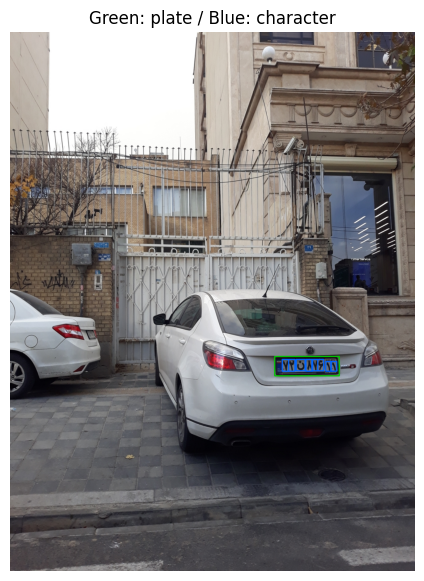

In [4]:
# Draw reference annotations for visual inspection, not model predictions.
example = selected[selected["split"] == "train"].iloc[0]
example_image = cv2.imread(os.path.join(ROOT, example["image"]))
for box in box_groups[int(example["id"])]:
    x1, y1, x2, y2 = map(int, (box["x1"], box["y1"], box["x2"], box["y2"]))
    color = (0, 200, 0) if box["label"] == PLATE_LABEL else (255, 100, 0)
    cv2.rectangle(example_image, (x1, y1), (x2, y2), color, 2)
plt.figure(figsize=(7, 7))
# Convert OpenCV's BGR channels to RGB for correct Matplotlib colors.
plt.imshow(cv2.cvtColor(example_image, cv2.COLOR_BGR2RGB))
plt.title("Green: plate / Blue: character")
plt.axis("off")
plt.show()

## 4. Build Datasets for Both YOLO Models

The plate detector receives full images. The character detector receives complete plate crops.

Every crop stays in its source image's split. Plates without character annotations are not treated as negative background samples.


In [5]:
def prepare_yolo(task, folder, source_images):
    # Use one plate class or all character classes; mapping converts names to IDs.
    names = [PLATE_LABEL] if task == "plate" else CLASSES
    mapping = {name: i for i, name in enumerate(names)}
    notes = []
    # Keep every crop in its source split to prevent leakage between data splits.
    for split in ("train", "validation", "test"):
        image_folder = os.path.join(folder, "images", split)
        label_folder = os.path.join(folder, "labels", split)
        os.makedirs(image_folder, exist_ok=True)
        os.makedirs(label_folder, exist_ok=True)
        paths = []
        for row in source_images[source_images["split"] == split].to_dict("records"):
            source = os.path.join(ROOT, row["image"])
            # Reject files changed since preparation rather than train with stale annotations.
            if file_hash(source) != row["image_sha256"] or file_hash(os.path.join(ROOT, row["xml"])) != row["xml_sha256"]:
                raise ValueError("Source changed since audit: " + source)
            image = cv2.imread(source)
            objects = box_groups[int(row["id"])]
            # The plate model uses full images; the character model uses reference plate crops.
            regions = [[0, 0, row["width"], row["height"]]] if task == "plate" else [
                [b["x1"], b["y1"], b["x2"], b["y2"]] for b in objects if b["label"] == PLATE_LABEL]
            # Report characters whose centers cannot be assigned to any plate crop.
            if task == "characters":
                for b in objects:
                    cx, cy = (b["x1"] + b["x2"]) / 2, (b["y1"] + b["y2"]) / 2
                    if b["label"] != PLATE_LABEL and not any(a <= cx < c and bb <= cy < d for a, bb, c, d in regions):
                        notes.append({"image_id": row["id"], "reason": "character_outside_all_plates"})
            for index, region in enumerate(regions):
                rx1, ry1, rx2, ry2 = crop_coordinates(region, row["width"], row["height"])
                width, height = rx2-rx1, ry2-ry1
                lines = []
                for b in objects:
                    # Keep plate boxes for the detector and character boxes for the reader.
                    if (task == "plate") != (b["label"] == PLATE_LABEL):
                        continue
                    cx, cy = (b["x1"] + b["x2"]) / 2, (b["y1"] + b["y2"]) / 2
                    # Assign a box to this region only when its center falls inside it.
                    if not (region[0] <= cx < region[2] and region[1] <= cy < region[3]):
                        continue
                    # Clip boxes to the crop and move their origin from the source image to the crop.
                    x1, x2 = max(b["x1"], rx1)-rx1, min(b["x2"], rx2)-rx1
                    y1, y2 = max(b["y1"], ry1)-ry1, min(b["y2"], ry2)-ry1
                    if x2 <= x1 or y2 <= y1:
                        raise ValueError("Empty clipped character box")
                    if task == "characters" and (x1+rx1, y1+ry1, x2+rx1, y2+ry1) != (b["x1"], b["y1"], b["x2"], b["y2"]):
                        notes.append({"image_id": row["id"], "reason": "character_clipped_to_plate"})
                    # YOLO rows contain class ID, center x/y, and width/height normalized to the region.
                    lines.append(f"{mapping[b['label']]} {(x1+x2)/2/width:.9f} {(y1+y2)/2/height:.9f} {(x2-x1)/width:.9f} {(y2-y1)/height:.9f}")
                # Missing character annotations do not imply an empty plate; do not create a negative sample.
                if task == "characters" and not lines:
                    notes.append({"image_id": row["id"], "reason": "plate_without_character_labels"})
                    continue
                stem = f"{int(row['id']):06d}_{index}"
                image_path = os.path.join(image_folder, stem + ".jpg")
                if task == "plate":
                    shutil.copy2(source, image_path)
                else:
                    # Enlarge tiny crops for YOLO; proportional resizing preserves normalized box coordinates.
                    crop, _, _ = minimum_size(image[ry1:ry2, rx1:rx2])
                    if not cv2.imwrite(image_path, crop):
                        raise OSError(image_path)
                with open(os.path.join(label_folder, stem + ".txt"), "w", encoding="utf-8") as stream:
                    stream.write("\n".join(dict.fromkeys(lines)))
                paths.append(os.path.abspath(image_path).replace(os.sep, "/"))
        # This TXT lists image paths; it is separate from each image's annotation TXT.
        with open(os.path.join(folder, split + ".txt"), "w", encoding="utf-8") as stream:
            stream.write("\n".join(paths))
        print(task, split, len(paths))
    # YOLO reads split lists and the class-ID mapping from this YAML file.
    with open(os.path.join(folder, "data.yaml"), "w", encoding="utf-8") as stream:
        yaml.safe_dump({"path": os.path.abspath(folder).replace(os.sep, "/"), "train": "train.txt",
                        "val": "validation.txt", "test": "test.txt", "names": dict(enumerate(names))},
                       stream, allow_unicode=True, sort_keys=False)
    pd.DataFrame(notes, columns=["image_id", "reason"]).to_csv(os.path.join(folder, "conversion_notes.csv"), index=False)
    return os.path.join(folder, "data.yaml")

training_images = selected
# Smoke samples only train and validation; its metrics are not model-quality evidence.
if MODE == "smoke":
    parts = []
    for split, limit in (("train", 16), ("validation", 4)):
        part = selected[selected["split"] == split]
        parts.append(part.iloc[np.linspace(0, len(part)-1, min(limit, len(part)), dtype=int)])
    training_images = pd.concat(parts)
if MODE != "saved":
    # Use a separate run folder so earlier datasets and model files are not overwritten.
    RUN_FOLDER = os.path.join(OUTPUT_FOLDER, MODE + "_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
    os.makedirs(RUN_FOLDER, exist_ok=False)
    plate_data = prepare_yolo("plate", os.path.join(RUN_FOLDER, "plate_data"), training_images)
    character_data = prepare_yolo("characters", os.path.join(RUN_FOLDER, "character_data"), training_images)
    MODEL_FOLDER = os.path.join(RUN_FOLDER, "models")
    os.makedirs(MODEL_FOLDER)

## 5. Train, Save, and Reload YOLO Models

Both models start from pretrained COCO weights. `smoke` runs only one epoch and does not provide evidence of model quality.

`train` is a long-running operation. The previous full experiment took approximately 1.5 hours of training on an RTX 4070 Laptop GPU; runtime may vary.

New models are saved in a separate run directory without overwriting existing models.


In [6]:
def train_yolo(task, data_path, epochs, image_size, batch):
    # Transfer learning starts both models from COCO weights rather than random initialization.
    initial_weights = os.path.join(ROOT, "models", "yolov8n.pt")
    if not os.path.isfile(initial_weights):
        raise FileNotFoundError("Place the documented COCO yolov8n.pt in models before training.")
    # Disable flips to preserve writing direction; character augmentations are milder.
    options = dict(epochs=epochs, imgsz=image_size, batch=batch, device=DEVICE, workers=0,
                   # patience monitors validation improvement; AdamW and lr0 control weight updates.
                   seed=SEED, deterministic=True, patience=12, optimizer="AdamW", lr0=0.001,
                   cos_lr=True, fliplr=0.0, flipud=0.0, degrees=5 if task == "plate" else 3,
                   translate=0.1 if task == "plate" else 0.05, scale=0.3 if task == "plate" else 0.2,
                   hsv_h=0.015 if task == "plate" else 0.0, hsv_s=0.3 if task == "plate" else 0.2,
                   hsv_v=0.35 if task == "plate" else 0.3,
                   # Enable Mosaic only for plates and disable it near the scheduled end of training.
                   mosaic=0.5 if task == "plate" else 0.0, close_mosaic=10 if task == "plate" else 0,
                   # AMP can reduce GPU memory use; class-agnostic NMS is enabled only for characters.
                   mixup=0.0, cache=False, amp=DEVICE != "cpu", plots=True, agnostic_nms=task == "characters")
    # Override full-training settings for a short pipeline check, not a quality benchmark.
    if MODE == "smoke":
        options.update(epochs=1, imgsz=320, batch=2, amp=False, close_mosaic=0)
    # Record the effective settings after applying smoke overrides.
    pd.DataFrame([options]).to_csv(os.path.join(RUN_FOLDER, task + "_training_settings.csv"), index=False)
    model = YOLO(initial_weights)
    result = model.train(data=data_path, project=os.path.join(RUN_FOLDER, "training"), name=task, **options)
    # Select weights by validation performance, which may differ from the final epoch.
    best = os.path.join(str(model.trainer.save_dir), "weights", "best.pt")
    destination = os.path.join(MODEL_FOLDER, "plate_detector.pt" if task == "plate" else "character_detector.pt")
    shutil.copy2(best, destination)
    # Reload the saved best checkpoint instead of using the last in-memory training state.
    return YOLO(destination)

if MODE != "saved":
    # Record package versions with the run to help explain environment-dependent differences.
    environment = {name: importlib.metadata.version(name) for name in
                   ("torch", "torchvision", "ultralytics", "numpy", "opencv-python", "scikit-learn", "pandas")}
    environment.update(seed=SEED, device=DEVICE, cuda=torch.version.cuda)
    pd.DataFrame([environment]).to_csv(os.path.join(RUN_FOLDER, "environment.csv"), index=False)
    # Train the two models sequentially; saved mode loads both without starting training.
    plate_model = train_yolo("plate", plate_data, PLATE_EPOCHS, 640, 16)
    character_model = train_yolo("characters", character_data, CHARACTER_EPOCHS, 320, 32)
else:
    plate_model, character_model, settings = load_models(MODEL_FOLDER)
    print("Loaded the previously trained models; no training was started.")

Loaded the previously trained models; no training was started.


## 6. Select Confidence Thresholds Using Validation Only

Compare the plate detector's F1 score across confidence thresholds. Select the character threshold from the mean per-class F1 curve.

In `smoke` mode, the provisional threshold of 0.25 is used only to check the pipeline and is not recommended for deployment.


In [7]:
# IoU is intersection area divided by union area for [x1, y1, x2, y2] boxes.
def box_iou(a, b):
    intersection = max(0, min(a[2], b[2])-max(a[0], b[0])) * max(0, min(a[3], b[3])-max(a[1], b[1]))
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - intersection
    return intersection / max(union, 1e-9)

def match_plates(predictions, truth):
    matches, used = [], set()
    # Match greedily in descending confidence order; each reference plate is used at most once.
    for i in sorted(range(len(predictions)), key=lambda i: -predictions[i]["confidence"]):
        # IoU >= 0.5 accepts a spatial match; confidence filtering is a separate threshold.
        candidates = [j for j in range(len(truth)) if j not in used and box_iou(predictions[i]["box"], truth[j]) >= 0.5]
        if candidates:
            j = max(candidates, key=lambda j: box_iou(predictions[i]["box"], truth[j]))
            matches.append((i, j))
            used.add(j)
    # Return matched pairs, extra detections (FP), and missed reference plates (FN).
    return matches, len(predictions)-len(matches), len(truth)-len(matches)

def ground_truth(image_id):
    return [[b["x1"], b["y1"], b["x2"], b["y2"]] for b in box_groups[int(image_id)] if b["label"] == PLATE_LABEL]

if MODE != "saved":
    plate_size = 320 if MODE == "smoke" else 640
    # Low confidence retains candidates for evaluation; iou=0.7 here controls NMS.
    val_plate = plate_model.val(data=plate_data, split="val", imgsz=plate_size, device=DEVICE,
                                workers=0, batch=4, conf=0.001, iou=0.7, plots=False,
                                project=RUN_FOLDER, name="validation_plate")
    # Character metrics use reference plate crops and do not include plate-detector errors.
    val_characters = character_model.val(data=character_data, split="val", imgsz=320, device=DEVICE,
                                         workers=0, batch=4, conf=0.001, iou=0.7, agnostic_nms=True, plots=False,
                                         project=RUN_FOLDER, name="validation_characters")
    # Smoke uses provisional thresholds; deployment thresholds are selected below in train mode.
    plate_confidence, character_confidence = 0.25, 0.25
    if MODE == "train":
        # Cache validation predictions once rather than rerun the model for each threshold.
        cached = []
        for row in training_images[training_images["split"] == "validation"].to_dict("records"):
            result = plate_model.predict(os.path.join(ROOT, row["image"]), conf=0.001, imgsz=640,
                                         device=DEVICE, iou=0.7, verbose=False)[0]
            predictions = [{"box": box, "confidence": score} for box, score in
                           zip(result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist())]
            cached.append((predictions, ground_truth(row["id"])))
        # Compare thresholds on validation only; never use test to select these settings.
        sweep = []
        for threshold in np.arange(0.05, 0.96, 0.05):
            tp = fp = fn = 0
            for predictions, truth in cached:
                matches, extra, missed = match_plates([p for p in predictions if p["confidence"] >= threshold], truth)
                tp, fp, fn = tp+len(matches), fp+extra, fn+missed
            # Precision measures correctness of detections; recall measures coverage of reference plates.
            precision, recall = tp/max(tp+fp, 1), tp/max(tp+fn, 1)
            sweep.append({"confidence": threshold, "F1": 2*precision*recall/max(precision+recall, 1e-9)})
        best = max(sweep, key=lambda row: row["F1"])
        # Maximize mean per-class character F1, not exact full-plate text accuracy.
        mean_f1 = val_characters.box.f1_curve.mean(axis=0)
        if best["F1"] <= 0 or mean_f1.max() <= 0:
            raise ValueError("Validation F1 is zero; do not export deployment settings.")
        plate_confidence = best["confidence"]
        character_confidence = float(val_characters.box.px[np.argmax(mean_f1)])
        pd.DataFrame(sweep).to_csv(os.path.join(RUN_FOLDER, "plate_threshold_selection.csv"), index=False)
    # Save thresholds and input sizes with checkpoint hashes before final-test evaluation.
    settings_rows = []
    for kind, confidence, size in (("plate", plate_confidence, plate_size), ("character", character_confidence, 320)):
        filename = kind + "_detector.pt"
        settings_rows.append({"model": kind, "filename": filename, "confidence": confidence,
                              "image_size": size, "sha256": file_hash(os.path.join(MODEL_FOLDER, filename))})
    pd.DataFrame(settings_rows).to_csv(os.path.join(MODEL_FOLDER, "settings.csv"), index=False)
    plate_model, character_model, settings = load_models(MODEL_FOLDER)
display(pd.DataFrame(settings.values()))

,model,filename,confidence,image_size,sha256
0,plate,plate_detector.pt,0.5,640,8efe9eed2d3c0304c4320a5d1e16ba0d7a82fdf1173821...
1,character,character_detector.pt,0.21021021021021022,320,b380a44361a5eb6f6bf239bcb8d49c311db9499d3b6d9b...


## 7. Evaluate Detection, Full-Plate Text, and Errors

Plate detection mAP differs from exact full-plate text accuracy. Reference text is reconstructed from XML annotations and may be incomplete.

Missed eligible plates count as text errors. Plates without character annotations are excluded from the text-accuracy denominator and counted separately.

`saved` only loads verified historical reports. In `train` mode, test evaluation happens after the settings are fixed. This test set has already been used; evaluating it again does not provide a new independent estimate.


,model,scope,precision,recall,mAP50,mAP50_95,accuracy,CER,images,text_eligible_plates,macro_F1,character_crops
0,YOLO plate,test: plate detection,0.957155,0.953568,0.98359,0.775293,,,,,,
1,YOLO characters,test: character detection on GT plate crops,0.903458,0.872366,0.874775,0.528249,,,,,,
2,YOLO full pipeline,test: reconstructed XML text; missed plates co...,0.945643,0.953212,,,0.858086,0.064209,4113.0,4848.0,,
3,HOG + SVM,validation: classification of GT character cro...,,,,,0.894326,,,,0.751098,18945.0


Stored verified results from the previous full experiment; not a new evaluation.


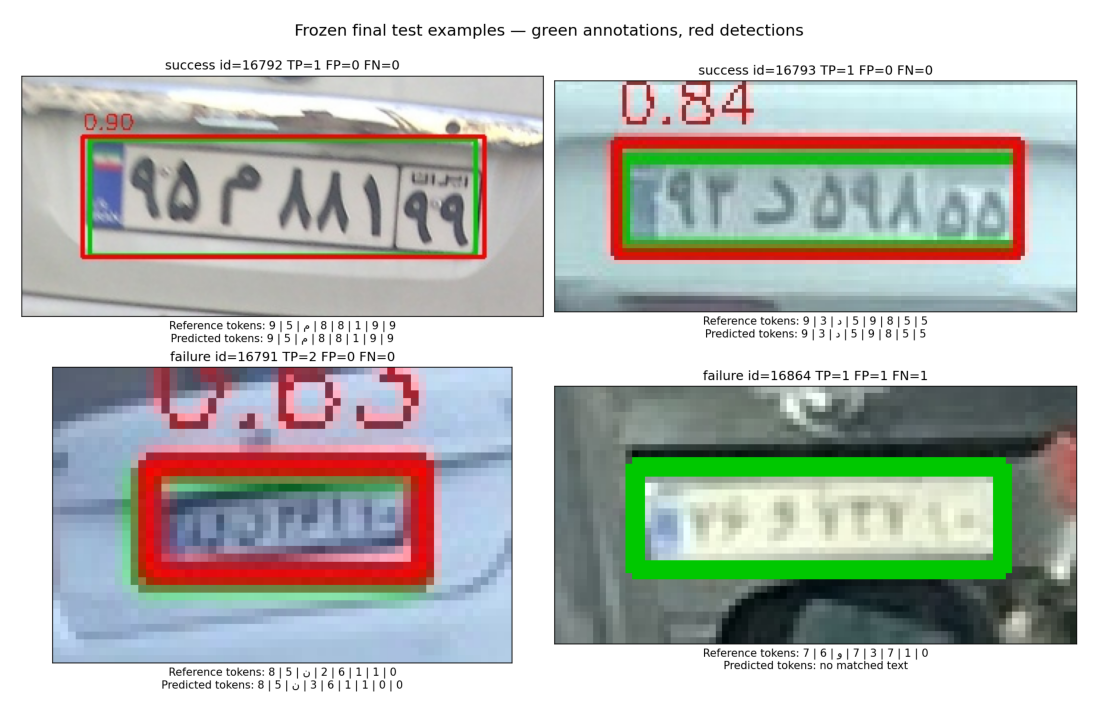

In [8]:
# Reconstruct reference text from XML classes in spatial left-to-right order; labels may be incomplete.
def expected_text(image_id, plate_box):
    x1, y1, x2, y2 = plate_box
    chars = [b for b in box_groups[int(image_id)] if b["label"] != PLATE_LABEL
             and x1 <= (b["x1"]+b["x2"])/2 < x2 and y1 <= (b["y1"]+b["y2"])/2 < y2]
    chars.sort(key=lambda b: (b["x1"]+b["x2"])/2)
    return "".join(character_symbol(b["label"]) for b in chars)

# Edit distance counts the fewest insertions, deletions, and substitutions between two texts.
def text_distance(expected, predicted):
    previous = list(range(len(predicted)+1))
    for i, a in enumerate(expected, 1):
        current = [i]
        for j, b in enumerate(predicted, 1):
            current.append(min(current[-1]+1, previous[j]+1, previous[j-1]+int(a != b)))
        previous = current
    return previous[-1]

def evaluate_text(source_images, split):
    tp = fp = fn = eligible = correct = edits = characters = empty = 0
    details, examples = [], {"success": 0, "failure": 0}
    for row in source_images[source_images["split"] == split].to_dict("records"):
        image = cv2.imread(os.path.join(ROOT, row["image"]))
        # Evaluate the full pipeline: the plate detector's predicted crop goes into the character model.
        predictions = read_plates(image, plate_model, character_model, settings, DEVICE)
        truth = ground_truth(row["id"])
        matches, extra, missed = match_plates(predictions, truth)
        tp, fp, fn = tp+len(matches), fp+extra, fn+missed
        matched = {j: predictions[i]["text"] for i, j in matches}
        reference = [expected_text(row["id"], box) for box in truth]
        for j, text in enumerate(reference):
            # Exclude plates without character references from text accuracy and count them separately.
            if not text:
                empty += 1
                continue
            eligible += 1
            # A missed eligible plate gets an empty prediction and remains an error in text accuracy.
            correct += int(matched.get(j, "") == text)
            # CER divides total edit operations by the total number of reference characters.
            edits += text_distance(text, matched.get(j, ""))
            characters += len(text)
            details.append({"image_id": row["id"], "reference": text, "prediction": matched.get(j, "")})
        # Save a few successes and failures for inspection; examples do not replace aggregate metrics.
        category = "success" if all(text and matched.get(j, "") == text for j, text in enumerate(reference)) and extra == 0 else "failure"
        if examples[category] < 3:
            draw_plates(predictions).save(os.path.join(RUN_FOLDER, f"{split}_{category}_{row['id']}.png"))
            examples[category] += 1
    pd.DataFrame(details).to_csv(os.path.join(RUN_FOLDER, split + "_texts.csv"), index=False, encoding="utf-8-sig")
    return {"model": "YOLO full pipeline", "scope": split + ": reconstructed XML text",
            "precision": tp/max(tp+fp, 1), "recall": tp/max(tp+fn, 1), "accuracy": correct/max(eligible, 1),
            "CER": edits/max(characters, 1), "tp": tp, "fp": fp, "fn": fn,
            "text_eligible_plates": eligible, "plates_without_character_labels": empty}

measured_rows = []
if MODE == "saved":
    # saved displays verified historical results rather than performing a new evaluation.
    measured = pd.read_csv(os.path.join(ROOT, "assets", "verified_metrics.csv"))
    display(measured.fillna(""))
    print("Stored verified results from the previous full experiment; not a new evaluation.")
    example_path = os.path.join(ROOT, "assets", "verified_examples.png")
    plt.figure(figsize=(14, 9))
    plt.imshow(Image.open(example_path))
    plt.axis("off")
    plt.show()
else:
    for name, result in (("YOLO plate", val_plate), ("YOLO characters on GT plate crops", val_characters)):
        measured_rows.append({"model": name, "scope": "validation", "precision": result.box.mp,
                              "recall": result.box.mr, "mAP50": result.box.map50, "mAP50_95": result.box.map})
    measured_rows.append(evaluate_text(training_images, "validation"))
    # Evaluate test only after settings are saved; this test set is already consumed, not a fresh holdout.
    if MODE == "train":
        # Settings have been saved before the first final-test evaluation.
        for name, model, data_path, size in (("YOLO plate", plate_model, plate_data, 640),
                                             ("YOLO characters on GT plate crops", character_model, character_data, 320)):
            result = model.val(data=data_path, split="test", imgsz=size, device=DEVICE, workers=0, batch=4,
                               iou=0.7, agnostic_nms="characters" in name, plots=True,
                               project=RUN_FOLDER, name="test_" + ("characters" if "characters" in name else "plate"))
            measured_rows.append({"model": name, "scope": "test (previously consumed)", "precision": result.box.mp,
                                  "recall": result.box.mr, "mAP50": result.box.map50, "mAP50_95": result.box.map})
        measured_rows.append(evaluate_text(training_images, "test"))
    measured = pd.DataFrame(measured_rows)
    measured.to_csv(os.path.join(RUN_FOLDER, "metrics.csv"), index=False)
    display(measured.fillna(""))
    print("Smoke checks are not model-quality evidence." if MODE == "smoke" else "This is a new run, not the historical experiment.")

## 8. Predict on a New Image Using the Loaded Models


,plate,text,confidence,perspective_applied
0,1,29د72863,0.769433,False


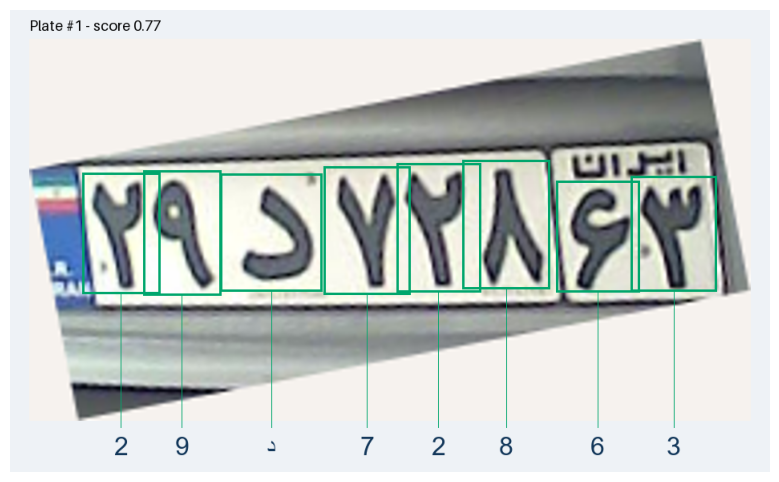

In [9]:
# Use the same saved models and settings for a new image; no retraining is needed.
if os.path.isfile(NEW_IMAGE):
    new_image = cv2.imread(NEW_IMAGE)
    # Perspective correction is experimental and defaults off after an overall validation regression.
    predictions = read_plates(new_image, plate_model, character_model, settings, DEVICE, RECTIFY_NEW_IMAGE)
    display(pd.DataFrame([{"plate": i, "text": p["text"], "confidence": p["confidence"],
                           "perspective_applied": p["perspective_applied"]} for i, p in enumerate(predictions, 1)]))
    plt.figure(figsize=(13, 6))
    plt.imshow(draw_plates(predictions))
    plt.axis("off")
    plt.show()
else:
    print("Set NEW_IMAGE to an existing JPG or PNG path to try another image.")

## 9. Classical Baseline: HOG + SVM

This model classifies a single character crop with a known bounding box. It does not locate plates or characters.

Training and validation crops inherit their source image's split. The test set is not used for this baseline.


In [10]:
# This baseline classifies reference character crops; it does not detect plates or characters.
def svm_data(source_images, split):
    features, labels = [], []
    for row in source_images[source_images["split"] == split].to_dict("records"):
        image = cv2.imread(os.path.join(ROOT, row["image"]))
        plates = ground_truth(row["id"])
        for box in box_groups[int(row["id"])]:
            if box["label"] == PLATE_LABEL:
                continue
            cx, cy = (box["x1"]+box["x2"])/2, (box["y1"]+box["y2"])/2
            if not any(a <= cx < c and b <= cy < d for a, b, c, d in plates):
                continue
            x1, y1, x2, y2 = crop_coordinates([box["x1"], box["y1"], box["x2"], box["y2"]], row["width"], row["height"])
            # Use the shared HOG preprocessing so feature extraction stays consistent during inference.
            features.append(character_features(image[y1:y2, x1:x2]))
            labels.append(box["label"])
    return np.asarray(features, dtype=np.float32), np.asarray(labels)

if MODE == "saved":
    svm_model = joblib.load(os.path.join(MODEL_FOLDER, "character_svm.joblib"))["model"]
    display(pd.read_csv(os.path.join(ROOT, "assets", "svm_settings.csv")))
    display(pd.read_csv(os.path.join(ROOT, "assets", "svm_class_report.csv"), dtype={"label": str}))
    print("Loaded SVM and its previously measured validation report.")
else:
    # Use train and validation only; each character crop inherits its source image's split.
    x_train, y_train = svm_data(training_images, "train")
    x_val, y_val = svm_data(training_images, "validation")
    # The shared label list is for reporting; validation features are never passed to fit.
    labels = sorted(set(y_train) | set(y_val))
    candidates, best_score, svm_model = [], -1, None
    with threadpool_limits(limits=4):
        # Select C by validation macro F1 so each reported class contributes equally.
        for c in (0.1, 1.0):
            candidate = LinearSVC(C=c, dual="auto", random_state=SEED, max_iter=5000)
            with warnings.catch_warnings():
                # Treat non-convergence as an error instead of silently reporting an unfinished fit.
                warnings.simplefilter("error", ConvergenceWarning)
                candidate.fit(x_train, y_train)
            predicted = candidate.predict(x_val)
            macro_f1 = f1_score(y_val, predicted, labels=labels, average="macro", zero_division=0)
            candidates.append({"C": c, "validation_accuracy": accuracy_score(y_val, predicted), "macro_F1": macro_f1})
            if macro_f1 > best_score:
                svm_model, best_score = candidate, macro_f1
    # Save the selected train-only model without refitting on validation; its score is not independent test evidence.
    path = os.path.join(MODEL_FOLDER, "character_svm.joblib")
    joblib.dump({"model": svm_model}, path)
    before_reload = svm_model.predict(x_val)
    svm_model = joblib.load(path)["model"]
    svm_predictions = svm_model.predict(x_val)
    # Serialization must preserve every validation prediction exactly.
    np.testing.assert_array_equal(before_reload, svm_predictions)
    # Per-class reports and the confusion matrix expose weaknesses hidden by aggregate accuracy.
    report = classification_report(y_val, svm_predictions, labels=labels, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.to_csv(os.path.join(RUN_FOLDER, "svm_class_report.csv"), encoding="utf-8-sig")
    pd.DataFrame(confusion_matrix(y_val, svm_predictions, labels=labels), index=labels, columns=labels).to_csv(
        os.path.join(RUN_FOLDER, "svm_confusion.csv"), encoding="utf-8-sig")
    pd.DataFrame(candidates).to_csv(os.path.join(RUN_FOLDER, "svm_selection.csv"), index=False)
    measured_rows.append({"model": "HOG + SVM", "scope": "validation: GT character classification; selected on validation",
                          "accuracy": accuracy_score(y_val, svm_predictions), "macro_F1": best_score})
    measured = pd.DataFrame(measured_rows)
    measured.to_csv(os.path.join(RUN_FOLDER, "metrics.csv"), index=False)
    display(pd.DataFrame(candidates))

,C,train_crops,validation_crops,seed,model_sha256,scope
0,1.0,132114,18945,42,ac64c6ac4b388cc8e2ab480b783e4ec20a5a69f947e41d...,classification of ground-truth character crops...


,label,precision,recall,f1-score,support
0,0,0.784314,0.836237,0.809444,287.0
1,1,0.905295,0.940940,0.922773,2235.0
2,2,0.814937,0.814043,0.814490,1823.0
3,3,0.810110,0.775434,0.792393,1612.0
4,4,0.867089,0.881802,0.874384,1709.0
5,5,0.915159,0.927894,0.921482,1581.0
6,6,0.932049,0.938234,0.935131,1959.0
7,7,0.906173,0.894032,0.900061,1642.0
8,8,0.939778,0.936316,0.938044,1900.0
9,9,0.921483,0.931129,0.926281,1815.0


Loaded SVM and its previously measured validation report.


## 10. Results Summary and Comparison Limits

Read each metric together with the model, task, and data split.

SVM accuracy on reference character crops is not directly comparable to the YOLO pipeline's exact full-plate text accuracy. Validation scores used for model or threshold selection are not independent test results.

Dataset limitations include blur, small plates, underrepresented classes, incomplete annotations, and possible vehicle or scene overlap.


In [11]:
# Read task and split alongside each metric; SVM character accuracy is not full-plate reading accuracy.
columns = [name for name in ("model", "scope", "precision", "recall", "mAP50", "mAP50_95", "accuracy", "CER", "macro_F1")
           if name in measured.columns]
display(measured[columns].fillna(""))
if MODE == "saved":
    print("These are verified historical results. The simplified version has not been trained for 60 epochs again.")
print("SVM: provided character boxes. YOLO pipeline: predicted plate and character boxes.")

,model,scope,precision,recall,mAP50,mAP50_95,accuracy,CER,macro_F1
0,YOLO plate,test: plate detection,0.957155,0.953568,0.98359,0.775293,,,
1,YOLO characters,test: character detection on GT plate crops,0.903458,0.872366,0.874775,0.528249,,,
2,YOLO full pipeline,test: reconstructed XML text; missed plates co...,0.945643,0.953212,,,0.858086,0.064209,
3,HOG + SVM,validation: classification of GT character cro...,,,,,0.894326,,0.751098


These are verified historical results. The simplified version has not been trained for 60 epochs again.
SVM: provided character boxes. YOLO pipeline: predicted plate and character boxes.
